# EfficientNet_05: EfficientNet-B0, grouped split (34 species, unseen recordings), 3 seeds

**Change vs 03: checkpoint selection, early stopping and LR scheduler use validation macro-F1 instead of validation loss** (as in REPSOL).
Why: in 02b/03/04 the best epoch was almost always epoch 1. On unseen recordings the val loss rises from epoch 1 (over-confident mistakes) while val accuracy keeps improving (e.g. 04: 24 % → 37 % over 5 epochs), so stopping on loss kept an under-trained model.
lr 1e-4, weight decay 1e-2, max 15 epochs, patience 4 (on val F1).

Everything else is the 2025 recipe (see `EfficientNet_02.ipynb`). **Selection rule:** runs are compared on mean
*validation* macro-F1 over seeds 42/43/44; test metrics are recorded but not used for choosing.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
from src.EfficientNet.experiment import run_seeds
RUN = "EfficientNet_05"
df = run_seeds(RUN, split="grouped", augment=False, lr=1e-4, weight_decay=1e-2, max_epochs=15, patience=4, select_metric="val_f1")
df

device=cuda | classes=34 | train=9502 val=2102 test=2057


Epoch 1/15 | train loss 1.6148 acc 71.12 | val loss 3.0676 acc 41.44 F1 0.310 | lr 1.00e-04 | 197s


  saved best checkpoint -> efficientnet_05_s42_best_01.pth


Epoch 2/15 | train loss 0.4182 acc 92.57 | val loss 3.2515 acc 39.11 F1 0.294 | lr 1.00e-04 | 46s


Epoch 3/15 | train loss 0.1833 acc 96.36 | val loss 3.6775 acc 42.63 F1 0.341 | lr 1.00e-04 | 62s


  saved best checkpoint -> efficientnet_05_s42_best_01.pth


... (60 outputs left out)

Epoch 15/15 | train loss 0.0118 acc 99.55 | val loss 5.9697 acc 43.72 F1 0.335 | lr 1.00e-04 | 37s


Training finished.


--> EfficientNet_05_s44: val F1 0.351 acc 0.441 | best epoch 12/15


,run,seed,split,config,best_epoch,epochs_run,val_loss,val_acc,val_f1_macro,test_acc,test_f1_macro,minutes
0,EfficientNet_05,42,grouped,"{""augment"": false, ""lr"": 0.0001, ""weight_decay...",6,10,4.0263,0.4719,0.3686,0.6650,0.4738,16.5
1,EfficientNet_05,43,grouped,"{""augment"": false, ""lr"": 0.0001, ""weight_decay...",11,15,4.9649,0.5262,0.3734,0.6553,0.4749,22.1
2,EfficientNet_05,44,grouped,"{""augment"": false, ""lr"": 0.0001, ""weight_decay...",12,15,6.3408,0.4410,0.3506,0.6529,0.5034,9.2


In [3]:
df[["val_f1_macro", "val_acc", "test_f1_macro", "test_acc", "best_epoch"]].agg(["mean", "std"]).round(3)

,val_f1_macro,val_acc,test_f1_macro,test_acc,best_epoch
mean,0.364,0.480,0.484,0.658,9.667
std,0.012,0.043,0.017,0.006,3.215


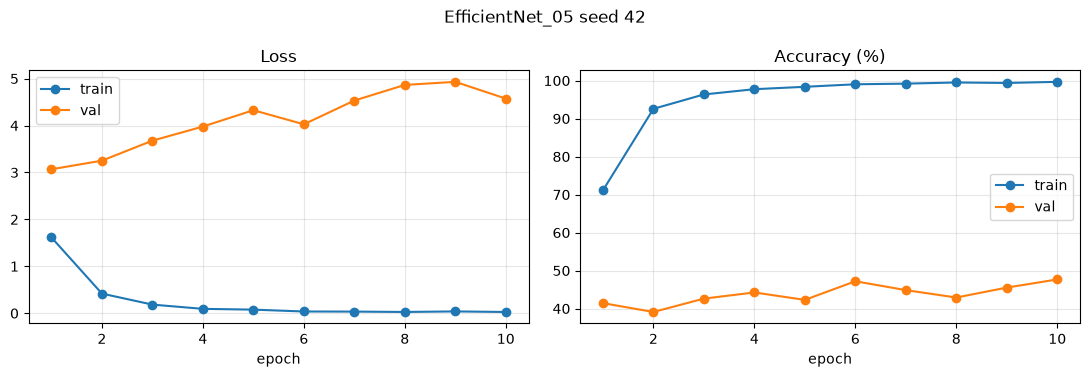

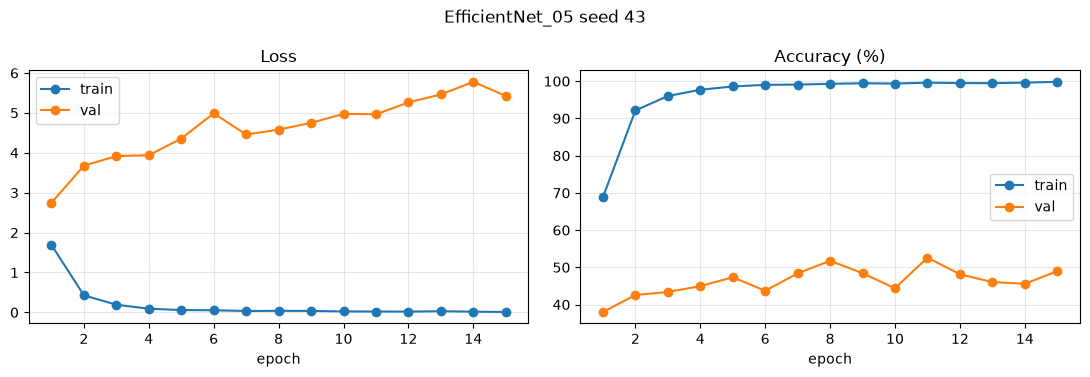

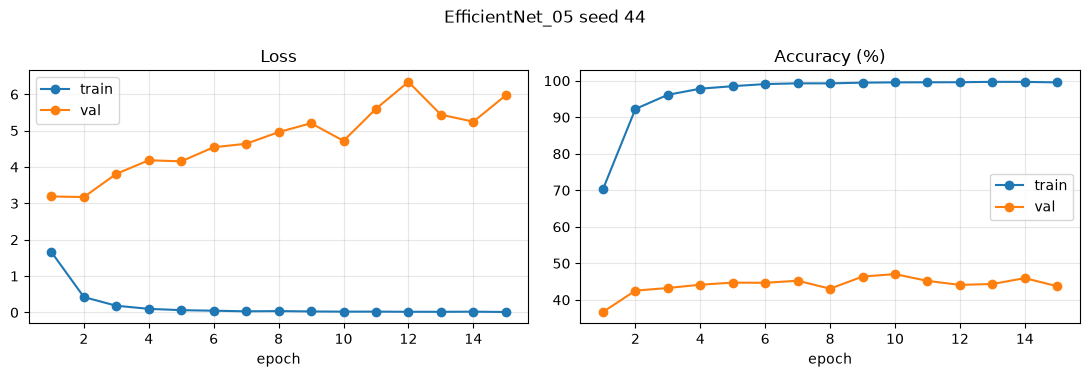

In [4]:
from src.plot_analysis import plot_learning_curves
import matplotlib.pyplot as plt
for s in df.seed:
    h = sorted(config.MODELS_OUTPUT.glob(f"{RUN.lower()}_s{s}_best_*_training_history.csv"))[-1]
    plot_learning_curves(h, f"{RUN} seed {s}", config.EVAL_DIR / f"learning_curves_{RUN}_s{s}.png"); plt.show()